# Hồi quy tuyến tính với Gradient Descent (GD)
Giải tích ma trận qua phương trình chuẩn $\mathcal{O}(D^3)$ trở nên quá đắt đỏ khi số lượng đặc trưng $D$ rất lớn. Thay vào đó, ta sử dụng phương pháp lặp Gradient Descent để tối ưu hóa hàm mất mát[cite: 3].

Hàm mất mát Mean Squared Error (MSE) cho mô hình tuyến tính:
$$\mathcal{L}(w) = \frac{1}{2N} ||\Phi w - y||_2^2$$

Đạo hàm (Gradient) của hàm mất mát theo trọng số $w$ áp dụng quy tắc chuỗi (Chain Rule)[cite: 2]:
$$\nabla_w \mathcal{L} = \Phi^T \frac{\partial \mathcal{L}}{\partial \hat{y}}$$
Trong đó $\frac{\partial \mathcal{L}}{\partial \hat{y}} = \frac{1}{N}(\hat{y} - y)$ là ma trận truyền ngược (backward) từ lớp `MeanSquaredError`[cite: 3]. Đạo hàm này chỉ ra hướng tăng dốc nhất của bề mặt hàm mất mát[cite: 2].

Quy tắc cập nhật trọng số tại mỗi bước lặp $t$ với tốc độ học (learning rate) $\eta$[cite: 3]:
$$w^{(t+1)} = w^{(t)} - \eta \nabla_w \mathcal{L}(w^{(t)})$$

In [1]:
import numpy as np
from utils.losses import MeanSquaredError

class LinearRegressionGD:
    """Hồi quy tuyến tính tối ưu bằng Gradient Descent Batch."""
    def __init__(self, learning_rate=0.1, epochs=100, fit_intercept=True):
        self.lr = learning_rate
        self.epochs = epochs
        self.fit_intercept = fit_intercept
        self.weights = None
        self.intercept = None
        self.loss_history = []
        self.mse = MeanSquaredError() # Kế thừa engine toán học

    def fit(self, X: np.ndarray, y: np.ndarray):
        X = np.asarray(X)
        y = np.asarray(y).reshape(-1, 1)
        N = X.shape[0]

        if self.fit_intercept:
            Phi = np.hstack([np.ones((N, 1), dtype=X.dtype), X])
        else:
            Phi = X

        # Khởi tạo trọng số ngẫu nhiên
        np.random.seed(42)
        w = np.random.randn(Phi.shape[1], 1) * 0.01

        for _ in range(self.epochs):
            # Forward pass
            y_pred = Phi @ w
            
            # Tính và lưu Loss
            loss = self.mse.forward(y, y_pred)
            self.loss_history.append(loss)
            
            # Backward pass (Tính gradient)
            grad_y_pred = self.mse.backward(y, y_pred)
            grad_w = Phi.T @ grad_y_pred
            
            # Cập nhật trọng số
            w -= self.lr * grad_w

        if self.fit_intercept:
            self.intercept = float(w[0, 0])
            self.weights = w[1:].flatten()
        else:
            self.intercept = 0.0
            self.weights = w.flatten()
            
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.asarray(X) @ self.weights + self.intercept

Metric               | Scratch         | Sklearn (SGD)  
-------------------------------------------------------
R² Score             | 0.9702          | 0.9710         
Time (ms)            | 0.88            | 0.00           


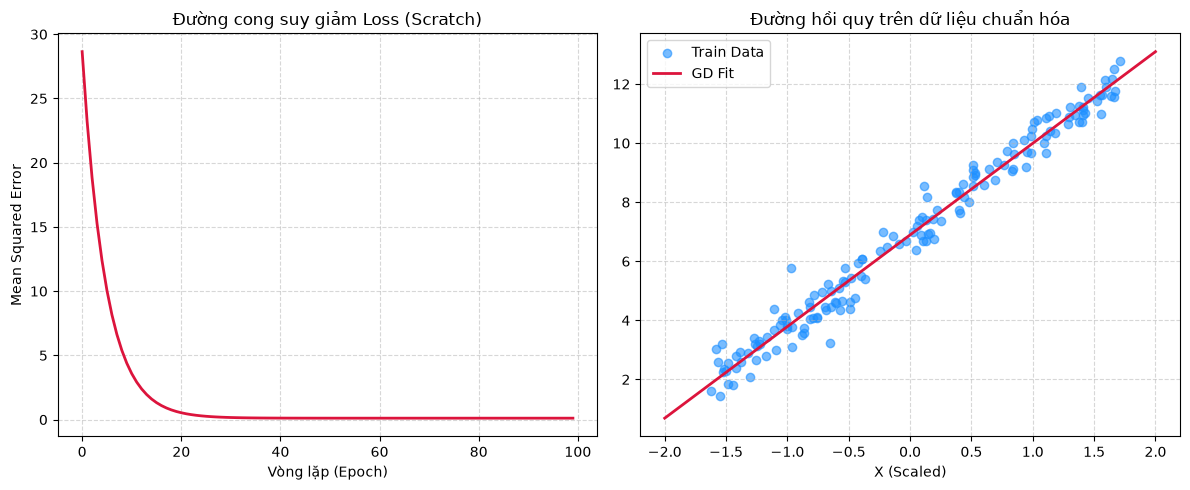

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor
from utils.metrics import r2_score
from utils.preprocessing import StandardScaler, train_test_split

# 1. Sinh dữ liệu thực nghiệm
np.random.seed(42)
X = 2.5 * np.random.rand(200, 1)
y = 4.2 * X.squeeze() + 1.8 + np.random.randn(200) * 0.5
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Chuẩn hóa dữ liệu (Cực kỳ quan trọng để GD hội tụ)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Huấn luyện model Scratch
t0 = time.time()
model_scratch = LinearRegressionGD(learning_rate=0.1, epochs=100).fit(X_train_scaled, y_train)
t_scratch = (time.time() - t0) * 1000

# 4. Huấn luyện model Sklearn (SGDRegressor)
t0 = time.time()
model_sklearn = SGDRegressor(learning_rate='constant', eta0=0.1, max_iter=100, random_state=42)
model_sklearn.fit(X_train_scaled, y_train)
t_sklearn = (time.time() - t0) * 1000

# 5. So sánh đối chuẩn
y_pred_scratch = model_scratch.predict(X_test_scaled)
y_pred_sklearn = model_sklearn.predict(X_test_scaled)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn (SGD)':<15}")
print("-" * 55)
print(f"{'R² Score':<20} | {r2_score(y_test, y_pred_scratch):<15.4f} | {r2_score(y_test, y_pred_sklearn):<15.4f}")
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")

# 6. Trực quan hóa
plt.figure(figsize=(12, 5))

# Đồ thị 1: Loss Curve
plt.subplot(1, 2, 1)
plt.plot(model_scratch.loss_history, color='crimson', linewidth=2)
plt.title("Đường cong suy giảm Loss (Scratch)")
plt.xlabel("Vòng lặp (Epoch)")
plt.ylabel("Mean Squared Error")
plt.grid(True, linestyle='--', alpha=0.5)

# Đồ thị 2: Đường hồi quy
plt.subplot(1, 2, 2)
plt.scatter(X_train_scaled, y_train, color='dodgerblue', alpha=0.6, label='Train Data')
x_plot = np.linspace(-2, 2, 100).reshape(-1, 1)
plt.plot(x_plot, model_scratch.predict(x_plot), color='crimson', linewidth=2, label='GD Fit')
plt.title("Đường hồi quy trên dữ liệu chuẩn hóa")
plt.xlabel("X (Scaled)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()